[*********************100%***********************]  5 of 5 completed
/var/folders/fv/2ms0d579387gvdzxhfmrjh1m0000gn/T/ipykernel_86989/1226171899.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(max_sharpe_port[1],max_sharpe_port[0],marker=(5,1,0),color='r',s=500)
/var/folders/fv/2ms0d579387gvdzxhfmrjh1m0000gn/T/ipykernel_86989/1226171899.py:112: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.scatter(min_vol_port[1],min_vol_port[0],marker=(5,1,0),color='g',s=500)


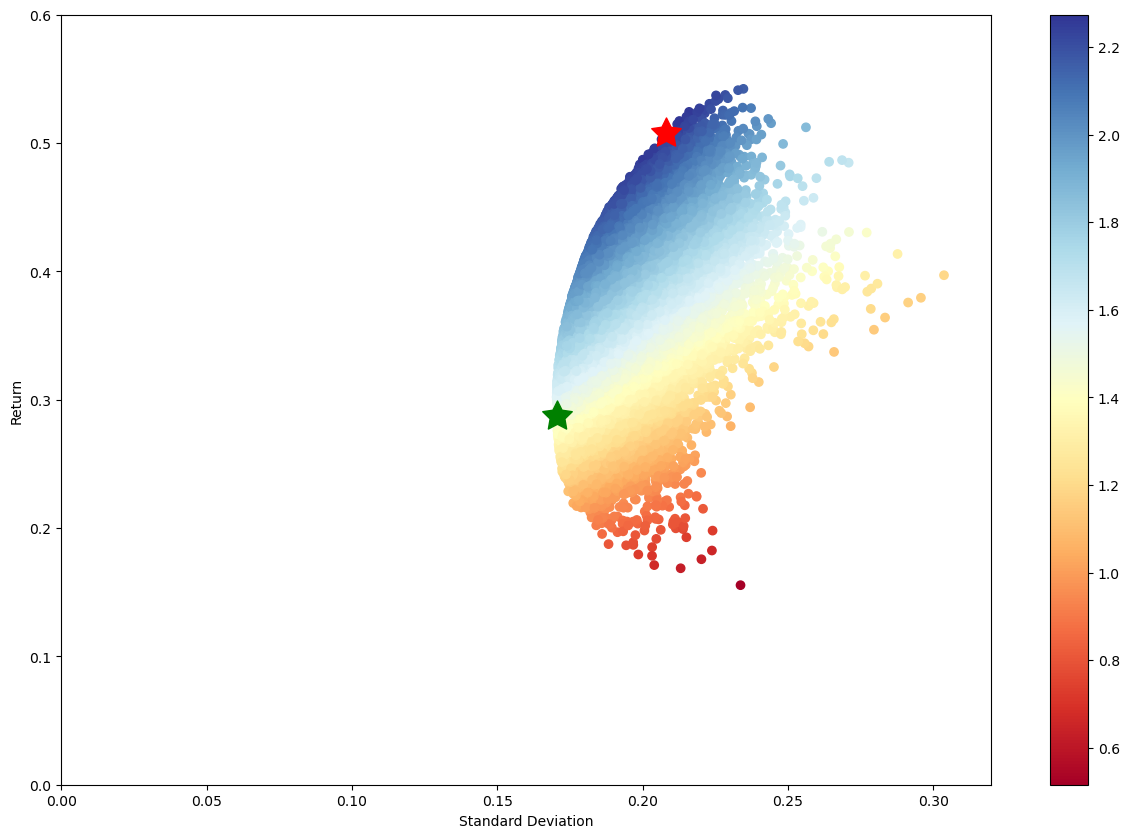

In [6]:
#### importing the packages we need ####
import pandas as pd
import numpy as np
import datetime
import matplotlib.pyplot as plt
import yfinance as yf

#### creating initial dataset ####

#creating a list with the name of the tickers we want to analize
tickers = ['EBS.VI', 'OMV.VI', 'UQA.VI', 'VER.VI', 'VOE.VI']

#Auto Adjust will overwrite the Close price by Adj Close, threads=True downloads several tickers at the same time --> faster
#for every stock we have open, close, high and low price together with the volume.
prices = yf.download(tickers, start="2021-01-01", end="2022-01-01", 
                     interval="1d", group_by='ticker', 
                     auto_adjust=True, threads=True)

#we create an empyt dataset
df = pd.DataFrame()

#we populate the dataset with the close price of the prices dataset subdivided by stock
#(meanin each column is a different stock with the close prices of the day)
for ticker in tickers:
    df[ticker] = prices[ticker]["Close"] 
#df.columns = tickers

#### Function definitions ####

#we define the function to calculate the portfolio performances:
def calc_portfolio_perf(weights, mean_returns, cov, rf):
    ''' 
    The input variable opf this functions are the weights, the mean_returns the covariance and the
    risk free rate. then it calculates the metrics for the portofolios
    ''' 
    #It multiplies the mean returns of the assets by their corresponding weights and then sums up the results. The product is then multiplied by 252, assuming 252 trading days in a year.
    portfolio_return = np.sum(mean_returns * weights) * 252 #annualized return
    
    # It takes the dot product of the weights transpose, the covariance matrix, and the weights themselves. The result is then square rooted and multiplied by the square root of 252 to annualize the value.
    portfolio_std = np.sqrt(np.dot(weights.T, np.dot(cov, weights))) * np.sqrt(252) # annualized volatility, np.dot execute a matrix multiplication
    sharpe_ratio = (portfolio_return - rf) / portfolio_std #formula sharpe ratio
    return portfolio_return, portfolio_std, sharpe_ratio

def simulate_random_portfolios(num_portfolios, mean_returns, cov, rf):
    ''' 
    This function is used to simulate n portfolios in order to see all the possible combinations of weight 
    of the assets on which we want to build the portfolio
    '''
    #we create a matric full of zeros, within the rows we use +3 cause is the numbe rof the calculation we add for each portfolio (portfolio_return, portfolio_std, sharpe_ratio)
    #the other elements of the rows are the weights associated with the assets of the considered portfolio
    #each column is a different portfolio with random weights 
    #The basic syntax for np.zeros is as follows: numpy.zeros(shape, dtype=float, order='C')
    results_matrix = np.zeros((len(mean_returns)+3, num_portfolios))
    for i in range(num_portfolios): #loop that iterates over all the portfolios
        weights = np.random.random(len(mean_returns)) #assigns a value [0,1] to the 'weights' variavle whose lenghts is the same as mean_returns
        weights /= np.sum(weights) #each weight is divided with the sum of the weights on order to sum to 1
        portfolio_return, portfolio_std, sharpe_ratio = calc_portfolio_perf(weights, mean_returns, cov, rf) #we define the metrics of the generated portofolios using the function defined before
        #we position this metrics in the first 3 rows for each portfolio
        results_matrix[0,i] = portfolio_return
        results_matrix[1,i] = portfolio_std
        results_matrix[2,i] = sharpe_ratio
        #with the second loop we add the weights under the portfolio_metrics for each portfolio
        for j in range(len(weights)):
            results_matrix[j+3,i] = weights[j] #it starts adding the weights from the j+3 rows so we do not overwrite the metrics
    #we rewrite the resulting dataframe in order that each row is a protfolio (we just transponse the result_matrix) 
    results_df = pd.DataFrame(results_matrix.T,columns=['Return','Standard_Deviation','Sharpe'] + [ticker for ticker in tickers]) 
    #the weights are associeted with the name of the asset so for each portofolio we see the corrisponding metrics and how much we have to put on each asset 
    return results_df


#### Empirical computation ####

## VERY IMPORTANT: we have the dataset with the Adj close prices not the RETURN of the asset. everything has to be computed on the RETURNS
## thats why we use pct_change, it is a shortcut istead of adding new columns to the dataset

#This code calculates the mean returns of each asset in a DataFrame df. 
# It uses the pct_change() function to compute the percentage change between consecutive elements in the DataFrame, and then applies the mean() function to calculate the average of these percentage changes.
mean_returns = df.pct_change().mean()

#This code calculates the covariance matrix of the returns for the assets in the DataFrame df. 
#It uses the pct_change() function to compute the percentage change between consecutive elements in the DataFrame, and then applies the cov() function to calculate the covariance matrix.
cov = df.pct_change().cov()

num_portfolios = 100000 #(i choose this)
rf = 0.035 #(i choose this, not really but i can do assumptions on this number, es: Euribor rate )

#final dataset using the functions we defined, we gave as input the variables and we obtain as result what we wrote in "def simulate_random_portfolios: "
results_frame = simulate_random_portfolios(num_portfolios, mean_returns, cov, rf)

#locate position of portfolio with highest Sharpe Ratio
#results_frame['Sharpe'] select the Sharpe column, idxmax gave the index of the row where we have the highest sharpe, iloc extract the rows with all the values
# NB: the pobject is a Panda series so not a matrix or dataframe, if we want that format we need to transform it.
max_sharpe_port = results_frame.iloc[results_frame['Sharpe'].idxmax()] 
#locate positon of portfolio with minimum standard deviation
min_vol_port = results_frame.iloc[results_frame['Standard_Deviation'].idxmin()]

#### PLOT ####

#This line creates a new figure and axes with a specific figure size of 15 inches in width and 10 inches in height. The figsize parameter controls the dimensions of the figure.
plt.subplots(figsize=(15,10))
#This line creates a scatter plot using the scatter function from matplotlib.
#It plots the values from the 'Standard_Deviation' column of the results_frame DataFrame on the x-axis and the values from the 'Return' column on the y-axis.
#The color of each point is determined by the values in the 'Sharpe' column, with a colormap specified as 'RdYlBu'. 
# This means that the color of the points will vary based on the Sharpe ratio values, with a red-to-yellow-to-blue color scheme.
plt.scatter(results_frame.Standard_Deviation,results_frame.Return,c=results_frame.Sharpe,cmap='RdYlBu')
plt.xlabel('Standard Deviation') #name of x-axis
plt.ylabel('Return') #name of y-axes 
plt.colorbar()
#plot red star to highlight position of portfolio with highest Sharpe Ratio
plt.scatter(max_sharpe_port[1],max_sharpe_port[0],marker=(5,1,0),color='r',s=500)
#plot green star to highlight position of minimum variance portfolio
plt.scatter(min_vol_port[1],min_vol_port[0],marker=(5,1,0),color='g',s=500)
#This line sets the limits for the x-axis, restricting the range between 0 and 0.32.
plt.xlim([0, 0.32])
#This line sets the limits for the y-axis, restricting the range between 0 and 0.6.
plt.ylim([0, 0.6])
plt.show()

/var/folders/fv/2ms0d579387gvdzxhfmrjh1m0000gn/T/ipykernel_86989/3909888191.py:10: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sharpe_port_return = max_sharpe_port[0]
/var/folders/fv/2ms0d579387gvdzxhfmrjh1m0000gn/T/ipykernel_86989/3909888191.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  sharpe_port_risk = max_sharpe_port[1]
/var/folders/fv/2ms0d579387gvdzxhfmrjh1m0000gn/T/ipykernel_86989/3909888191.py:38: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by pos

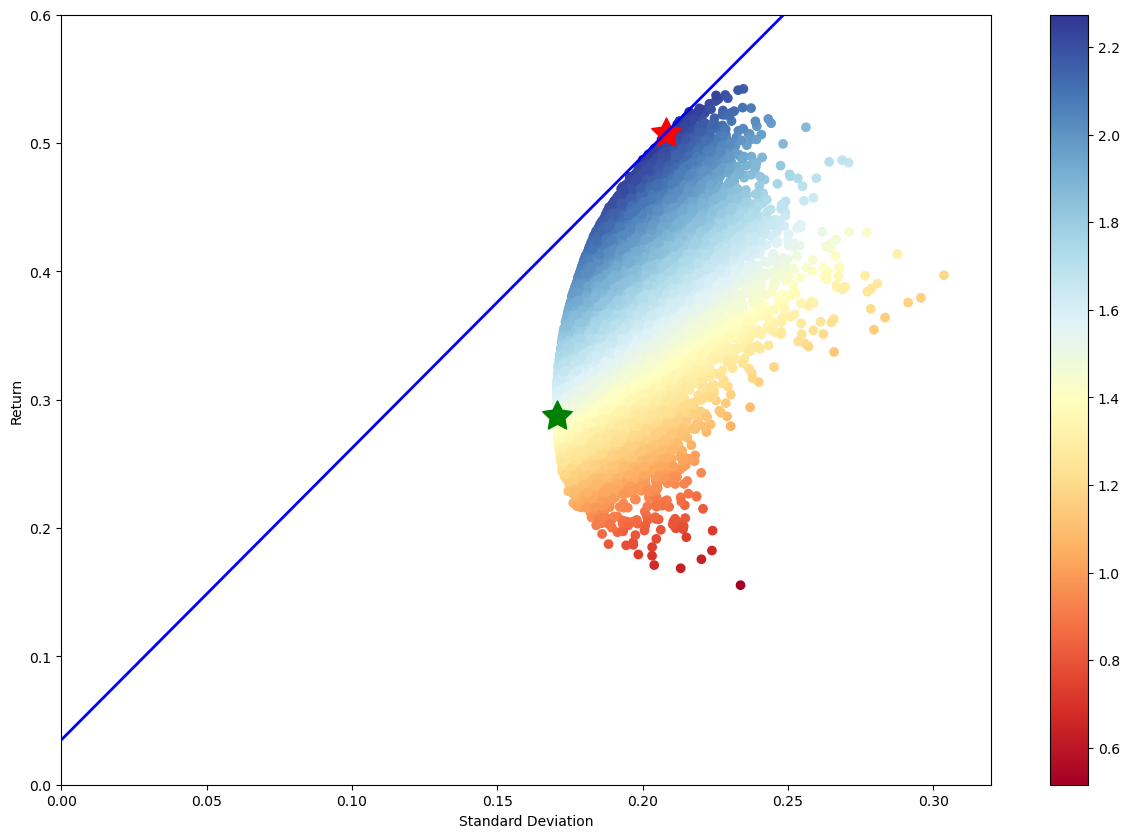

In [7]:
#### CAPITAL MARKET LINE ####

# The Capital Market Line (CML) is the straight line tangent to the efficient frontier
# at the maximum Sharpe ratio portfolio (the tangency portfolio), starting from the risk-free rate on the y-axis.

# Risk-free rate
rf = 0.035 #correspond to the value in x = 0 (vol = 0) so the certain return if we invest on a risk-free asset

# Maximum Sharpe Ratio portfolio (coordinates for plotting)
sharpe_port_return = max_sharpe_port[0] 
sharpe_port_risk = max_sharpe_port[1]

# Slope of the CML (Capital Market Line)
#obtained by simply writing the formula to find the angle of the line between two known points in a cartesian axes.
# P1(0, rf ) risk free
# P2(sharpe_port_risk, sharpe_port_return) #max sharpe coordinates
# slope = (y2 - y1)/(x2 - x1)
slope = (sharpe_port_return - rf) / sharpe_port_risk

# Generate CML points
x_cml = np.linspace(0, 0.32, 100)  # From risk-free risk (0) to maximum risk in the plot
y_cml = rf + slope * x_cml #i write the line function

#### PLOT ####

#This line creates a new figure and axes with a specific figure size of 15 inches in width and 10 inches in height. The figsize parameter controls the dimensions of the figure.
plt.subplots(figsize=(15,10))
plt.plot(x_cml, y_cml, label='Capital Market Line', color='blue', linestyle='-', linewidth=2)
#This line creates a scatter plot using the scatter function from matplotlib.
#It plots the values from the 'Standard_Deviation' column of the results_frame DataFrame on the x-axis and the values from the 'Return' column on the y-axis.
#The color of each point is determined by the values in the 'Sharpe' column, with a colormap specified as 'RdYlBu'. 
# This means that the color of the points will vary based on the Sharpe ratio values, with a red-to-yellow-to-blue color scheme.
plt.scatter(results_frame.Standard_Deviation,results_frame.Return,c=results_frame.Sharpe,cmap='RdYlBu')
plt.xlabel('Standard Deviation')
plt.ylabel('Return')
plt.colorbar()
#plot red star to highlight position of portfolio with highest Sharpe Ratio
plt.scatter(max_sharpe_port[1],max_sharpe_port[0],marker=(5,1,0),color='r',s=500)
#plot green star to highlight position of minimum variance portfolio
plt.scatter(min_vol_port[1],min_vol_port[0],marker=(5,1,0),color='g',s=500)
#This line sets the limits for the x-axis, restricting the range between 0 and 0.32.
plt.xlim([0, 0.32])
#This line sets the limits for the y-axis, restricting the range between 0 and 0.6.
plt.ylim([0, 0.6])
plt.show()


In [8]:
#This line converts the max_sharpe_port object into a pandas DataFrame using the to_frame() method.
#The resulting DataFrame will have a single row, where each column represents a property (e.g., 'Return', 'Standard_Deviation', 'Sharpe', and other columns corresponding to tickers if present).
max_sharpe_port.to_frame().T

,Return,Standard_Deviation,Sharpe,EBS.VI,OMV.VI,UQA.VI,VER.VI,VOE.VI
47078,0.50817,0.208124,2.273499,0.570373,0.158622,0.041447,0.229442,0.000116


In [9]:
#This line converts the min_vol_port object into a pandas DataFrame using the to_frame() method.
#The resulting DataFrame will have a single row, where each column represents a property (e.g., 'Return', 'Standard_Deviation', 'Sharpe', and other columns corresponding to tickers if present).
min_vol_port.to_frame().T

,Return,Standard_Deviation,Sharpe,EBS.VI,OMV.VI,UQA.VI,VER.VI,VOE.VI
71810,0.287198,0.17037,1.480296,0.068922,0.089805,0.45761,0.131737,0.251925


In [10]:
#to see how it looks the dataframe on which we constructed the plot:
print(results_frame)

         Return  Standard_Deviation    Sharpe    EBS.VI    OMV.VI    UQA.VI  \
0      0.304179            0.174890  1.539135  0.156355  0.051268  0.278914   
1      0.435610            0.202875  1.974665  0.360038  0.325412  0.185672   
2      0.475906            0.211402  2.085624  0.293956  0.457838  0.139909   
3      0.393304            0.188462  1.901202  0.418446  0.083218  0.347305   
4      0.391096            0.204903  1.737878  0.096823  0.401520  0.048863   
...         ...                 ...       ...       ...       ...       ...   
99995  0.334464            0.184177  1.625954  0.089226  0.220906  0.177984   
99996  0.359639            0.183699  1.767234  0.352570  0.007947  0.144022   
99997  0.356055            0.183193  1.752550  0.224891  0.006620  0.298653   
99998  0.341915            0.173893  1.764967  0.120285  0.194531  0.370876   
99999  0.422013            0.196292  1.971618  0.285456  0.226248  0.054671   

         VER.VI    VOE.VI  
0      0.196007  0.3174